In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

# Загрузка датасетов

In [2]:
df_1 = pd.read_csv('../data/proccessed_sunspots.csv', index_col=0)

In [3]:
df_1

,Month,Sunspots
0,1749-01-01,58.00
1,1749-02-01,62.60
2,1749-03-01,70.00
3,1749-04-01,55.70
4,1749-05-01,85.00
...,...,...
2815,1983-08-01,66.25
2816,1983-09-01,50.30
2817,1983-10-01,55.80
2818,1983-11-01,33.30


In [4]:
df_2 = pd.read_csv('../data/max_planck_weather_ts.csv', index_col=0, parse_dates=True)
df_2.index = pd.to_datetime(df_2.index, format='%d.%m.%Y %H:%M:%S')
df_2 = df_2.resample('D').mean()

In [5]:
df_2

,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
Date Time,,,,,,,,,,,,,,
2009-01-01,999.145594,-6.810629,266.414545,-8.015594,91.086014,3.691119,3.355524,0.335315,2.091049,3.357832,1305.178252,0.778601,1.378252,181.863077
2009-01-02,999.600625,-3.728194,269.463194,-4.824861,92.086806,4.640069,4.267292,0.373056,2.659792,4.268750,1290.353194,1.419514,2.227361,125.072014
2009-01-03,998.548611,-5.271736,268.002292,-9.015833,76.458056,4.184792,3.107708,1.077014,1.937778,3.111944,1297.117014,1.250903,2.065069,190.383333
2009-01-04,988.510694,-1.375208,272.685347,-2.897014,89.417361,5.524306,4.938958,0.584861,3.114028,4.997014,1264.634514,1.720417,3.564861,213.069861
2009-01-05,990.405694,-4.867153,269.039306,-6.797292,86.260417,4.362708,3.806736,0.555625,2.397014,3.847778,1284.372778,3.800278,5.940000,118.287361
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2016-12-28,1013.542986,4.887153,276.979444,2.408542,84.070833,8.672500,7.269583,1.403264,4.473264,7.171875,1266.425556,2.558194,4.726597,254.427708
2016-12-29,1013.957569,2.676250,274.744583,1.246458,90.384722,7.447569,6.705833,0.741250,4.123889,6.613542,1277.391528,0.837986,1.394028,196.642639
2016-12-30,1010.460278,-1.706597,270.647361,-2.727292,92.927083,5.465764,5.048542,0.416458,3.113889,4.996875,1294.402639,1.138125,1.839306,201.359028


# Генерация признаков

## 1 датасет

In [6]:
col = 'Sunspots'

lags = [1, 12, 130,]

for lag in lags:
    df_1[f'lag_{lag}'] = df_1[col].shift(lag)
    
df_1['diff_12'] = df_1[col].diff(12)
df_1['window_mean'] = df_1[col].shift(1).rolling(window=12).mean()
df_1 = df_1.dropna()
df_1.reset_index(inplace=True, drop=True)

In [7]:
X = df_1.drop(columns=['Sunspots', 'Month'])
y = df_1['Sunspots']
X_train_1, X_test_1, y_train_1, y_test_1 = train_test_split(X, y, test_size=0.2, shuffle=False)

In [8]:
X_train_1.head()

,lag_1,lag_12,lag_130,diff_12,window_mean
0,59.7,43.0,58.0,3.3,52.525000
1,46.3,43.0,62.6,14.0,52.800000
2,57.0,48.3,70.0,19.0,53.966667
3,67.3,44.0,55.7,15.5,55.550000
4,59.5,46.8,85.0,27.9,56.841667


## 2 датасет

In [9]:
col = 'T (degC)'

df_2['lag_1'] = df_2[col].shift(1)
df_2['lag_30'] = df_2[col].shift(30)
df_2['diff_1'] = df_2[col].diff(1)
df_2['window_mean'] = df_2[col].shift(1).rolling(window=7).mean()
df_2 = df_2.dropna()
df_2.reset_index(inplace=True, drop=True)

In [10]:
X = df_2.drop(columns=['T (degC)', 'Tpot (K)', 'Tdew (degC)'])
y = df_2['T (degC)']
X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(X, y, test_size=0.2, shuffle=False)

In [11]:
X_train_2.head()

,p (mbar),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg),lag_1,lag_30,diff_1,window_mean
0,994.375556,88.440278,5.275208,4.662222,0.612639,2.921181,4.688194,1275.224861,2.586597,4.006736,42.530764,-2.396042,-6.810629,0.394375,-1.189256
1,985.760694,83.506944,4.766875,3.975486,0.790833,2.512500,4.033611,1270.863125,3.938819,6.171736,44.648750,-2.001667,-3.728194,-1.358819,-1.843829
2,979.955833,80.692639,5.876597,4.694306,1.182153,2.985764,4.791528,1250.937639,1.483264,2.512431,126.700208,-3.360486,-5.271736,2.630764,-2.464573
3,973.867083,88.181736,6.231944,5.352639,0.879375,3.426181,5.496667,1239.755694,0.482708,0.970972,150.998056,-0.729722,-1.375208,0.686042,-2.099573
4,972.084028,91.938194,5.800278,5.233403,0.566667,3.356042,5.384236,1241.961667,0.857639,1.477500,168.881875,-0.043681,-4.867153,-0.972847,-1.913780


# CatBoost

In [12]:
from catboost import CatBoostRegressor

## 1 датасет

In [13]:
cb_model_1 = CatBoostRegressor(
    iterations=3000,
    learning_rate=0.05,
    depth=6,
    has_time=True,
    task_type='GPU',
    random_seed=42
)

In [14]:
cb_model_1.fit(X_train_1, y_train_1, eval_set=(X_test_1, y_test_1), verbose=500)

0:	learn: 36.1162946	test: 61.5807906	best: 61.5807906 (0)	total: 22.9ms	remaining: 1m 8s
500:	learn: 6.1107724	test: 16.5161346	best: 16.5161346 (500)	total: 3.29s	remaining: 16.4s
1000:	learn: 4.7291175	test: 15.4422895	best: 15.4343235 (934)	total: 6.48s	remaining: 12.9s
1500:	learn: 4.2552782	test: 14.7872409	best: 14.7802208 (1279)	total: 9.71s	remaining: 9.7s
2000:	learn: 4.2301540	test: 14.6864169	best: 14.6864169 (1922)	total: 12.8s	remaining: 6.41s
2500:	learn: 4.2301533	test: 14.6864159	best: 14.6864159 (2104)	total: 16.2s	remaining: 3.24s
2999:	learn: 4.2301536	test: 14.6864159	best: 14.6864159 (2104)	total: 19.6s	remaining: 0us
bestTest = 14.68641586
bestIteration = 2104
Shrink model to first 2105 iterations.


CatBoostRegressor(depth=6, has_time=True, iterations=3000, learning_rate=0.05, loss_function='RMSE', random_seed=42, task_type='GPU')

In [15]:
def predict_recursive(model, history_series, lags, n_steps):
    current_history = history_series.copy().tolist()
    forecast = []
    
    for step in range(n_steps):
        df_lags = {f'lag_{i}': i for i in lags}
        diff_12 = current_history[-1] - current_history[-13]
        window_mean = np.mean(current_history[-12:])
        X_next = pd.DataFrame([df_lags | {
            'diff_12': diff_12,
            'window_mean': window_mean
        }])
        
        pred = model.predict(X_next)[0]
        forecast.append(pred)
        current_history.append(pred)
        
    return pd.Series(forecast)

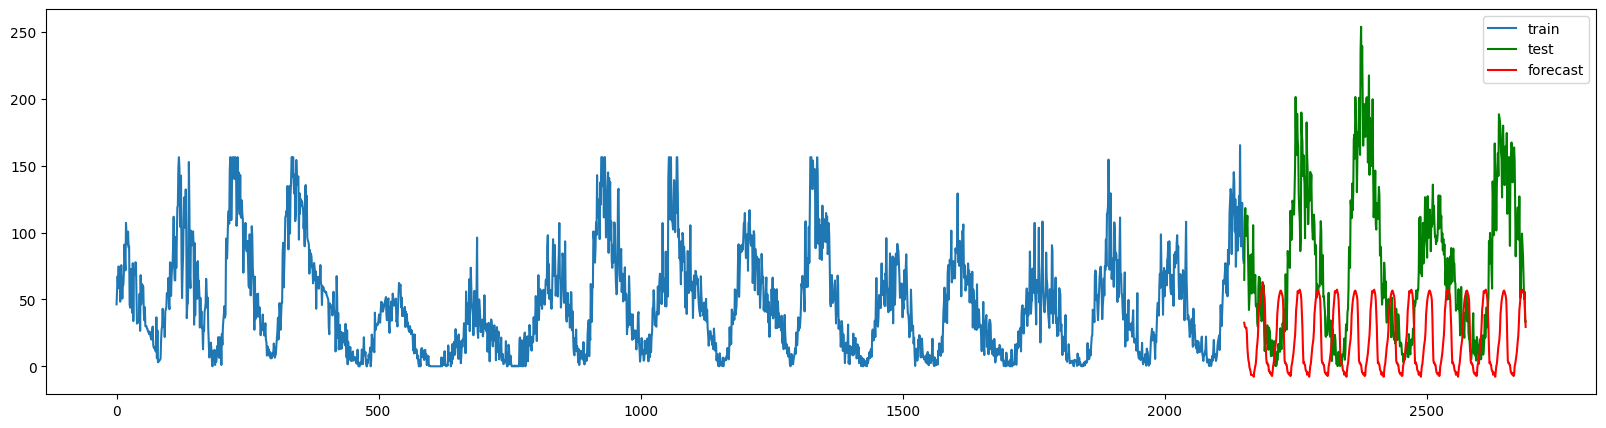

In [16]:
history = y_train_1.tail(130)

preds = predict_recursive(cb_model_1, history, lags, y_test_1.shape[0])
preds.index = y_test_1.index

plt.figure(figsize=(20, 5))
y_train_1.plot(label='train')
y_test_1.plot(label='test', c='g')
preds.plot(label='forecast', c='r')
plt.legend()

In [17]:
print(f"MAE: {mean_absolute_error(y_test_1, preds)}")
print(f"MSE: {mean_squared_error(y_test_1, preds)}")
print(f"MAPE: {mean_absolute_percentage_error(y_test_1, preds)}")
print(f"R2: {r2_score(y_test_1, preds)}")

MAE: 64.6589321725962
MSE: 6820.959292974934
MAPE: 2.187628854929432
R2: -1.1952617945448059


In [18]:
residuals = y_test_1 - preds
residuals = residuals.reset_index()
residuals['index'] = range(residuals.shape[0])
residuals = residuals.rename(columns={0: 'resid'})

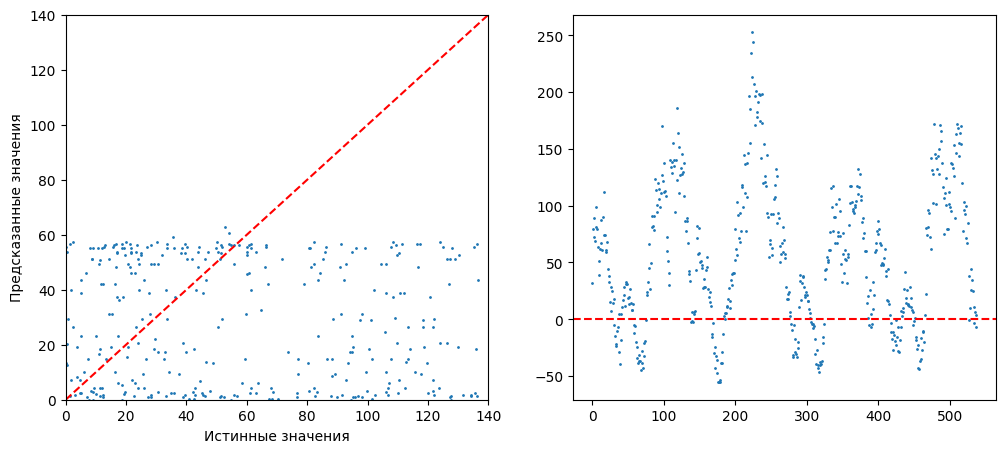

In [19]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(y_test_1, preds, s=1)
plt.axline((0, 0), (1, 1), color='red', linestyle='--')
plt.xlim(0, 140)
plt.ylim(0, 140)
plt.xlabel('Истинные значения')
plt.ylabel('Предсказанные значения')

plt.subplot(1, 2, 2)
plt.scatter(residuals['index'], residuals['resid'], s=1)
plt.axline((0, 0), (1, 0), color='red', linestyle='--')

## 2 датасет. Предсказание погоды на 1 день вперёд, зная данные влажности и т.д на данный день + сгенерированные временные признаки

In [20]:
cb_model_2 = CatBoostRegressor(
    iterations=2000,
    learning_rate=0.05,
    depth=6,
    has_time=True,
    task_type='GPU',
    random_seed=42
)

In [21]:
cb_model_2.fit(X_train_2, y_train_2, eval_set=(X_test_2, y_test_2), verbose=200, early_stopping_rounds=50)

0:	learn: 7.3974911	test: 7.5077449	best: 7.5077449 (0)	total: 13.8ms	remaining: 27.6s
200:	learn: 0.6398583	test: 0.6746334	best: 0.6746334 (200)	total: 1.64s	remaining: 14.6s
400:	learn: 0.6379975	test: 0.6708477	best: 0.6707628 (359)	total: 2.79s	remaining: 11.1s
bestTest = 0.6707627874
bestIteration = 359
Shrink model to first 360 iterations.


CatBoostRegressor(depth=6, has_time=True, iterations=2000, learning_rate=0.05, loss_function='RMSE', random_seed=42, task_type='GPU')

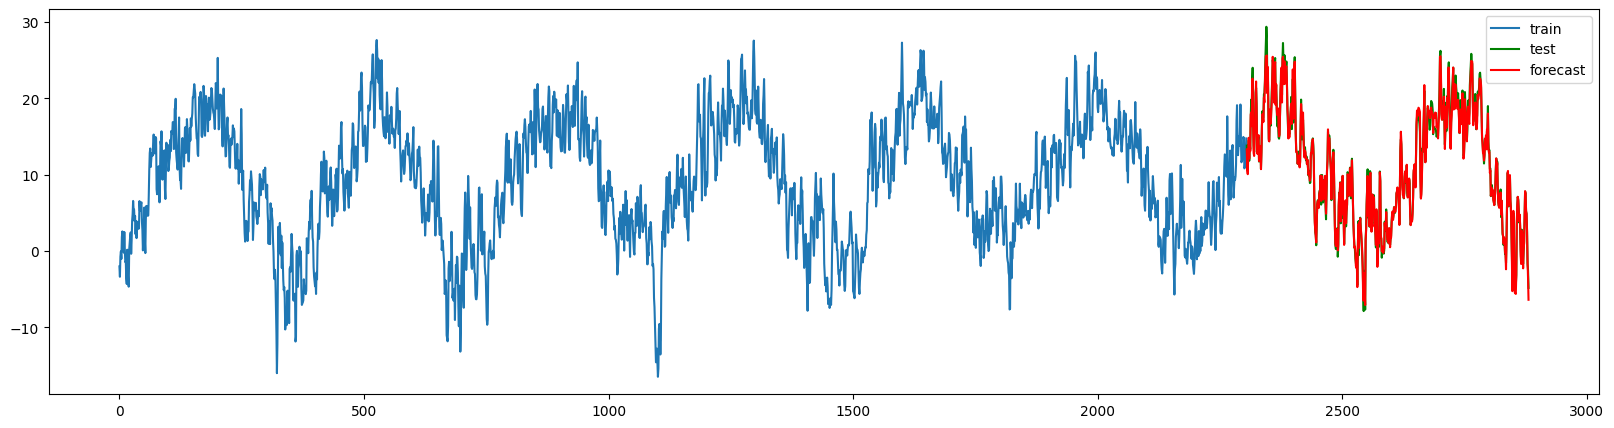

In [22]:
preds = cb_model_2.predict(X_test_2)
preds = pd.Series(preds, index=y_test_2.index)

plt.figure(figsize=(20, 5))
y_train_2.plot(label='train')
y_test_2.plot(label='test', c='g')
preds.plot(label='forecast', c='r')
plt.legend()

In [23]:
print(f"MAE: {mean_absolute_error(y_test_2, preds)}")
print(f"MSE: {mean_squared_error(y_test_2, preds)}")
print(f"MAPE: {mean_absolute_percentage_error(y_test_2, preds)}")
print(f"R2: {r2_score(y_test_2, preds)}")

MAE: 0.4579830439673185
MSE: 0.4499198932003456
MAPE: 0.12013909222644265
R2: 0.992059280549106


In [24]:
residuals = y_test_2 - preds
residuals = residuals.reset_index()
residuals['index'] = range(residuals.shape[0])
residuals = residuals.rename(columns={0: 'resid'})

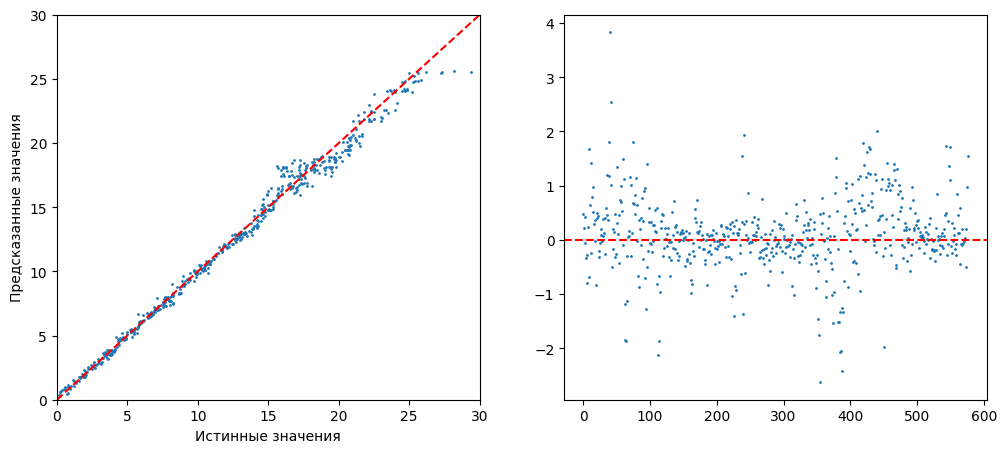

In [25]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(y_test_2, preds, s=1)
plt.axline((0, 0), (1, 1), color='red', linestyle='--')
plt.xlim(0, 30)
plt.ylim(0, 30)
plt.xlabel('Истинные значения')
plt.ylabel('Предсказанные значения')

plt.subplot(1, 2, 2)
plt.scatter(residuals['index'], residuals['resid'], s=1)
plt.axline((0, 0), (1, 0), color='red', linestyle='--')

# Глубокое обучение

In [26]:
from neuralforecast import NeuralForecast
from neuralforecast.models import DeepAR, NBEATS, TCN
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

## 2 датасет

In [29]:
df_2 = pd.read_csv('../data/max_planck_weather_ts.csv', index_col=0, parse_dates=True)
df_2.index = pd.to_datetime(df_2.index, format='%d.%m.%Y %H:%M:%S')

df_2 = df_2.resample('D').mean()
df_2 = df_2.interpolate(method='linear')

df_format = df_2.drop(columns=['Tpot (K)', 'Tdew (degC)']).reset_index()
df_format = df_format.rename(columns={df_format.columns[0]: 'ds', 'T (degC)': 'y'})
df_format['unique_id'] = 1  

features = [col for col in df_format.columns if col not in ['unique_id', 'ds', 'y']]

horizon = 30
train_df = df_format.iloc[:-horizon].copy()
test_df = df_format.iloc[-horizon:].copy()

input_size = 60 

models = [
    DeepAR(h=horizon, input_size=input_size, scaler_type='standard', max_steps=500),
    NBEATS(h=horizon, input_size=input_size, max_steps=500),
    TCN(h=horizon, input_size=input_size, max_steps=500) 
]

Seed set to 1
Seed set to 1
Seed set to 1


In [30]:
nf = NeuralForecast(models=models, freq='D')

nf.fit(df=train_df)

preds_df = nf.predict(df=train_df, futr_df=test_df)
preds_df = preds_df.reset_index()

Y_hat_df = test_df[['ds', 'y']].merge(preds_df, on='ds', how='left')

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name         | Type             | Params | Mode 
----------------------------------------------------------
0 | loss         | DistributionLoss | 5      | train
1 | valid_loss   | MAE              | 0      | train
2 | padder_train | ConstantPad1d    | 0      | train
3 | scaler       | TemporalNorm     | 0      | train
4 | hist_encoder | LSTM             | 199 K  | train
5 | decoder      | MLP              | 387    | train
----------------------------------------------------------
199 K     Trainable params
5         Non-trainable params
199 K     Total params
0.798     Total estimated model params size (MB)
8         Modules in train mode
0         Modules in eval mode


Sanity Checking: |                                                                               | 0/? [00:00<…

C:\Users\Denis\miniconda3\envs\myenv\lib\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |                                                                                      | 0/? [00:00<…

Validation: |                                                                                    | 0/? [00:00<…

...

Predicting: |                                                                                    | 0/? [00:00<…

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |                                                                                    | 0/? [00:00<…

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |                                                                                    | 0/? [00:00<…

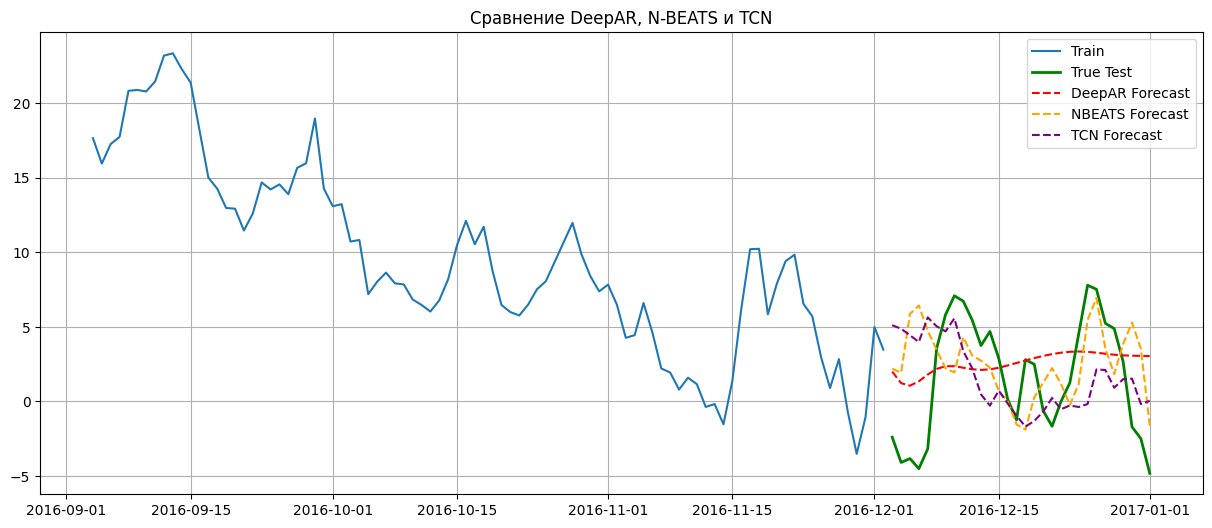

DeepAR | MAE: 3.3449 | R2: 0.0271
NBEATS | MAE: 3.4229 | R2: -0.2612
TCN | MAE: 3.7677 | R2: -0.4253


In [31]:
plt.figure(figsize=(15, 6))
plt.plot(train_df['ds'].tail(90), train_df['y'].tail(90), label='Train')
plt.plot(Y_hat_df['ds'], Y_hat_df['y'], label='True Test', c='g', linewidth=2)

plt.plot(Y_hat_df['ds'], Y_hat_df['DeepAR'], label='DeepAR Forecast', linestyle='--', c='r')
plt.plot(Y_hat_df['ds'], Y_hat_df['NBEATS'], label='NBEATS Forecast', linestyle='--', c='orange')
plt.plot(Y_hat_df['ds'], Y_hat_df['TCN'], label='TCN Forecast', linestyle='--', c='purple')

plt.title(f"Сравнение DeepAR, N-BEATS и TCN")
plt.grid(True)
plt.legend()
plt.show()

for model_name in ['DeepAR', 'NBEATS', 'TCN']:
    mae = mean_absolute_error(Y_hat_df['y'], Y_hat_df[model_name])
    r2 = r2_score(Y_hat_df['y'], Y_hat_df[model_name])
    print(f"{model_name} | MAE: {mae:.4f} | R2: {r2:.4f}")

## 1 датасет

In [32]:
df_1 = pd.read_csv('../data/proccessed_sunspots.csv', index_col=0)

In [33]:
df_processed = df_1.copy()
df_processed = df_processed.rename(columns={'Month': 'ds', 'Sunspots': 'y'})
df_processed['ds'] = pd.to_datetime(df_processed['ds'])
df_processed['unique_id'] = 1 

horizon = 24      
input_size = 72    

train_df = df_processed.iloc[:-horizon].copy()
test_df = df_processed.iloc[-horizon:].copy()

models = [
    DeepAR(h=horizon, input_size=input_size, scaler_type='standard', max_steps=500),
    NBEATS(h=horizon, input_size=input_size, max_steps=500),
]

nf = NeuralForecast(models=models, freq='MS')
nf.fit(df=train_df)

Seed set to 1
Seed set to 1
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name         | Type             | Params | Mode 
----------------------------------------------------------
0 | loss         | DistributionLoss | 5      | train
1 | valid_loss   | MAE              | 0      | train
2 | padder_train | ConstantPad1d    | 0      | train
3 | scaler       | TemporalNorm     | 0      | train
4 | hist_encoder | LSTM             | 199 K  | train
5 | decoder      | MLP              | 387    | train
----------------------------------------------------------
199 K     Trainable params
5         Non-trainable params
199 K     Total params
0.798     Total estimated model params size (MB)
8         Modules in train mode
0         Modules in eval mode


Sanity Checking: |                                                                               | 0/? [00:00<…

C:\Users\Denis\miniconda3\envs\myenv\lib\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |                                                                                      | 0/? [00:00<…

Validation: |                                                                                    | 0/? [00:00<…

...

Validation: |                                                                                    | 0/? [00:00<…

Validation: |                                                                                    | 0/? [00:00<…

Validation: |                                                                                    | 0/? [00:00<…

Validation: |                                                                                    | 0/? [00:00<…

`Trainer.fit` stopped: `max_steps=500` reached.


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
C:\Users\Denis\miniconda3\envs\myenv\lib\site-packages\pytorch_lightning\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Predicting: |                                                                                    | 0/? [00:00<…

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |                                                                                    | 0/? [00:00<…

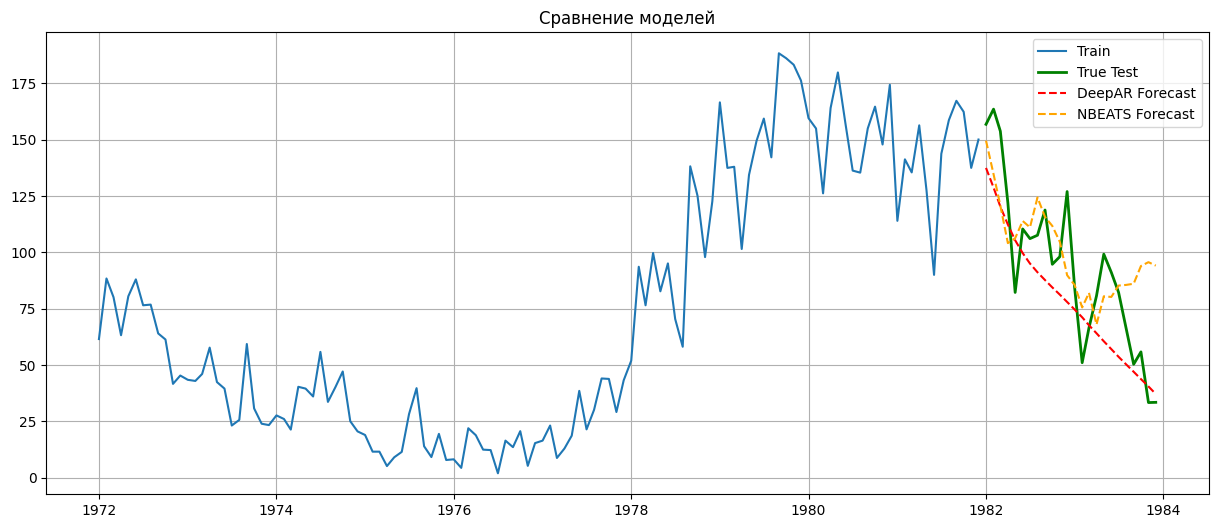

DeepAR | MAE: 19.0505 | R2: 0.5907
NBEATS | MAE: 20.9637 | R2: 0.4334


In [34]:
preds_df = nf.predict(df=train_df)
preds_df = preds_df.reset_index()

Y_hat_df = test_df[['ds', 'y']].merge(preds_df, on='ds', how='left')

plt.figure(figsize=(15, 6))
plt.plot(train_df['ds'].tail(120), train_df['y'].tail(120), label='Train')
plt.plot(Y_hat_df['ds'], Y_hat_df['y'], label='True Test', c='g', linewidth=2)

plt.plot(Y_hat_df['ds'], Y_hat_df['DeepAR'], label='DeepAR Forecast', linestyle='--', c='r')
plt.plot(Y_hat_df['ds'], Y_hat_df['NBEATS'], label='NBEATS Forecast', linestyle='--', c='orange')

plt.title(f"Сравнение моделей")
plt.grid(True)
plt.legend()
plt.show()

for model_name in ['DeepAR', 'NBEATS']:
    mae = mean_absolute_error(Y_hat_df['y'], Y_hat_df[model_name])
    r2 = r2_score(Y_hat_df['y'], Y_hat_df[model_name])
    print(f"{model_name} | MAE: {mae:.4f} | R2: {r2:.4f}")